# 🌲 Boscdex Indicator Tree Classifier Training on Google Colab (Free T4 GPU)

This notebook fine-tunes an on-device image classifier for **Boscdex Indicator Trees** using **MobileNetV2** and **Transfer Learning**.

### 🚀 Highlights:
1. **5 Core Catalan Indicator Trees:** *Pinus sylvestris* (Pi roig), *Pinus halepensis* (Pi blanc), *Quercus ilex* (Alzina), *Fagus sylvatica* (Faig), and *Castanea sativa* (Castanyer).
2. **Multi-Angle Field Curation:** Samples bark texture, foliage/needle closeups, and tree canopy silhouettes.
3. **1-Click Google Drive Ingestion & iNaturalist Auto-Top-Up:** Mounts Drive to search for `tree_dataset.zip` or automatically fetches research-grade Catalan/Spanish observations from iNaturalist.
4. **Decoupled Architecture Export:** Generates the quantized **TFLite feature extractor** (`tree_classifier.tflite`), the **binary projection head** (`tree_classifier_head.bin`), and `tree_labels.txt`—100% compatible with the Boscdex Flutter app!

### ⚡ Quick Start:
1. Ensure runtime is set to **T4 GPU** (`Runtime > Change runtime type > T4 GPU`).
2. Click **Runtime > Run all** (or run each cell sequentially).
3. When finished, your browser will automatically download the 3 updated model files ready to drop into `assets/models/`!


In [2]:
# Step 1: Verify Hardware & GPU Allocation
import sys
import platform
import shutil
import tensorflow as tf
import torch

print(f"Python Version:      {sys.version.split()[0]}")
print(f"Platform:            {platform.platform()}")
print(f"TensorFlow Version:  {tf.__version__}")
print(f"PyTorch Version:     {torch.__version__}")

if torch.cuda.is_available():
    print(f"✅ PyTorch GPU Active:    {torch.cuda.get_device_name(0)}")
else:
    print("⚠️ No PyTorch GPU detected. Select: Runtime > Change runtime type > T4 GPU.")

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ TensorFlow GPU Active: {gpus[0].name}")
    !nvidia-smi --query-gpu=name,memory.total,memory.free --format=csv,noheader
else:
    print("⚠️ No TF GPU detected.")


Python Version:      3.13.15
Platform:            Linux-6.6.122+-x86_64-with-glibc2.39
TensorFlow Version:  2.20.0
PyTorch Version:     2.11.0+cu128
✅ PyTorch GPU Active:    Tesla T4
✅ TensorFlow GPU Active: /physical_device:GPU:0
Tesla T4, 15360 MiB, 12734 MiB


In [3]:
# Step 2: Install Required Libraries
!pip install -q pyinaturalist requests pillow tqdm matplotlib scikit-learn


In [4]:
# Step 3: Species Catalog & Directory Structure
import os
from pathlib import Path

DATASET_DIR = Path("./dataset/trees")
EXPORT_DIR = Path("./export")
DATASET_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 5 Core Indicator Trees in Boscdex (folder_id, inaturalist_taxon_id, catalan_name, scientific_name)
TREE_CATALOG = [
    ("pinus_sylvestris", 47561, "Pi roig", "Pinus sylvestris"),
    ("pinus_halepensis", 82722, "Pi blanc", "Pinus halepensis"),
    ("quercus_ilex", 56133, "Alzina", "Quercus ilex"),
    ("fagus_sylvatica", 54227, "Faig", "Fagus sylvatica"),
    ("castanea_sativa", 121763, "Castanyer", "Castanea sativa"),
]

for t_id, _, _, _ in TREE_CATALOG:
    (DATASET_DIR / t_id).mkdir(parents=True, exist_ok=True)

print(f"✓ Configured {len(TREE_CATALOG)} tree species directories in {DATASET_DIR.resolve()}")


✓ Configured 5 tree species directories in /content/dataset/trees


In [13]:
# Step 4: Dataset Ingestion (Google Drive tree_dataset.zip or local upload)
import zipfile
import shutil

# 1. Mount Google Drive if running in Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    print('✅ Google Drive mounted successfully.')
except Exception as e:
    print(f'ℹ️ Google Drive mount note: {e}')

# 2. Check candidate locations for tree_dataset.zip
candidate_paths = [
    Path('/content/drive/MyDrive/tree_dataset.zip'),
    Path('/content/drive/MyDrive/boscdex/tree_dataset.zip'),
    Path('./tree_dataset.zip'),
]

found_archive = next((p for p in candidate_paths if p.exists()), None)

if found_archive:
    print(f'📦 Found dataset archive: {found_archive} ({found_archive.stat().st_size / (1024*1024):.1f} MB)')
    print('Extracting images into ./dataset/trees/...')
    with zipfile.ZipFile(found_archive, 'r') as zf:
        zf.extractall(DATASET_DIR.parent)
    print('✅ Extraction complete!')
else:
    print('ℹ️ No existing tree_dataset.zip found. Step 5 will auto-download research-grade field photos from iNaturalist!')

# 3. Print census
print()
print('📊 Initial Dataset Census by Species:')
total_images = 0
for t_id, _, cat_name, sci_name in TREE_CATALOG:
    folder = DATASET_DIR / t_id
    count = len(list(folder.glob('*.*'))) if folder.exists() else 0
    total_images += count
    print(f'  • {t_id.ljust(20)}: {count:3d} images ({cat_name} - {sci_name})')
print(f'Total tree images available: {total_images}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive mounted successfully.
📦 Found dataset archive: /content/drive/MyDrive/boscdex/tree_dataset.zip (60.4 MB)
Extracting images into ./dataset/trees/...
✅ Extraction complete!

📊 Initial Dataset Census by Species:
  • pinus_sylvestris    :  50 images (Pi roig - Pinus sylvestris)
  • pinus_halepensis    :  50 images (Pi blanc - Pinus halepensis)
  • quercus_ilex        :  50 images (Alzina - Quercus ilex)
  • fagus_sylvatica     :  50 images (Faig - Fagus sylvatica)
  • castanea_sativa     :  50 images (Castanyer - Castanea sativa)
Total tree images available: 250


In [6]:
# Step 5: iNaturalist Top-Up for Balanced Multi-Angle Classes (50+ photos per species)
import time
import io
from pathlib import Path
from PIL import Image
import requests
from tqdm.notebook import tqdm
from pyinaturalist import get_observations

# Target minimum photos per species covering foliage, bark, and habit
MIN_PHOTOS_PER_SPECIES = 50

# Geo places: Catalonia (7161), Spain (6774), Europe (97391)
PLACE_CATALONIA = 7161
PLACE_SPAIN = 6774
PLACE_EUROPE = 97391

HEADERS = {'User-Agent': 'Boscdex-Tree-Classifier/1.0'}

def download_and_crop(url, dest_path):
    try:
        resp = requests.get(url, headers=HEADERS, timeout=12)
        if resp.status_code == 200:
            img = Image.open(io.BytesIO(resp.content)).convert('RGB')
            w, h = img.size
            min_dim = min(w, h)
            left = (w - min_dim) // 2
            top = (h - min_dim) // 2
            img_cropped = img.crop((left, top, left + min_dim, top + min_dim))
            img_resized = img_cropped.resize((448, 448), Image.Resampling.LANCZOS)
            img_resized.save(dest_path, 'JPEG', quality=90)
            return True
    except Exception:
        return False
    return False

print(f'🌿 Ensuring all {len(TREE_CATALOG)} tree species have at least {MIN_PHOTOS_PER_SPECIES} photos...')

for t_id, taxon_id, cat_name, sci_name in tqdm(TREE_CATALOG, desc='Tree Taxa'):
    folder = DATASET_DIR / t_id
    existing = len(list(folder.glob('*.*')))
    needed = max(0, MIN_PHOTOS_PER_SPECIES - existing)

    if needed == 0:
        continue

    downloaded = 0
    for place_id in [PLACE_CATALONIA, PLACE_SPAIN, PLACE_EUROPE]:
        if downloaded >= needed:
            break
        try:
            obs = get_observations(
                taxon_id=taxon_id,
                place_id=place_id,
                quality_grade='research',
                photos=True,
                per_page=min(100, needed - downloaded + 15),
                order_by='votes'
            )

            for record in obs.get('results', []):
                if downloaded >= needed:
                    break
                for photo in record.get('photos', []):
                    if downloaded >= needed:
                        break
                    url = photo.get('url', '').replace('square', 'medium')
                    if not url:
                        continue
                    fname = f"{t_id}_inat_{existing + downloaded + 1}.jpg"
                    out_path = folder / fname
                    if out_path.exists():
                        continue
                    if download_and_crop(url, out_path):
                        downloaded += 1
                        time.sleep(0.08)
        except Exception as e:
            print(f'  ⚠️ Query note for {cat_name} (place {place_id}): {e}')

print('✅ Tree dataset census after curation:')
total_balanced = 0
for t_id, _, cat_name, sci_name in TREE_CATALOG:
    count = len(list((DATASET_DIR / t_id).glob('*.*')))
    total_balanced += count
    print(f'  • {t_id.ljust(20)}: {count:3d} images ({cat_name})')
print(f'Total images for training: {total_balanced}')


🌿 Ensuring all 5 tree species have at least 50 photos...


Tree Taxa:   0%|          | 0/5 [00:00<?, ?it/s]

✅ Tree dataset census after curation:
  • pinus_sylvestris    :  50 images (Pi roig)
  • pinus_halepensis    :  50 images (Pi blanc)
  • quercus_ilex        :  50 images (Alzina)
  • fagus_sylvatica     :  50 images (Faig)
  • castanea_sativa     :  50 images (Castanyer)
Total images for training: 250


In [7]:
# Step 6: Dataset Preprocessing & Data Augmentation Pipeline
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class TreeDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples  # list of (path, label_idx)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

# Build class mapping
label_names = [t[0] for t in TREE_CATALOG]
label_to_idx = {name: i for i, name in enumerate(label_names)}

all_samples = []
for t_id in label_names:
    folder = DATASET_DIR / t_id
    for img_path in folder.glob('*.*'):
        if img_path.suffix.lower() in ['.jpg', '.jpeg', '.png']:
            all_samples.append((str(img_path), label_to_idx[t_id]))

import random
random.seed(42)
random.shuffle(all_samples)

split_idx = int(0.8 * len(all_samples))
train_samples = all_samples[:split_idx]
val_samples = all_samples[split_idx:]

train_dataset = TreeDataset(train_samples, transform=train_transform)
val_dataset = TreeDataset(val_samples, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False, num_workers=2)

print(f'Train samples: {len(train_dataset)} | Validation samples: {len(val_dataset)}')


Train samples: 200 | Validation samples: 50


In [8]:
# Step 7: MobileNetV2 Deep Learning Feature Backbone
import torchvision.models as models
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Executing model training on: {device}')

# Load pre-trained MobileNetV2
backbone = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
# Extract features up to Global Average Pooling (1280 features)
feature_extractor = backbone.features
feature_extractor.eval()
feature_extractor.to(device)

# Freeze backbone
for param in feature_extractor.parameters():
    param.requires_grad = False

# Define Linear Projection Head (1280 -> 5 classes)
class TreeClassifierHead(nn.Module):
    def __init__(self, in_features=1280, num_classes=5):
        super().__init__()
        self.classifier = nn.Linear(in_features, num_classes)

    def forward(self, x):
        return self.classifier(x)

head = TreeClassifierHead(in_features=1280, num_classes=len(TREE_CATALOG)).to(device)
print(f'✓ Classification Head initialized: 1280 -> {len(TREE_CATALOG)} classes')


Executing model training on: cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 153MB/s]


✓ Classification Head initialized: 1280 -> 5 classes


In [9]:
# Step 8: Head Training & Multi-Class Calibration
import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(head.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=25)

EPOCHS = 30
best_val_acc = 0.0
best_weights = None
best_biases = None

for epoch in range(EPOCHS):
    head.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        with torch.no_grad():
            feats = feature_extractor(images)
            feats = nn.functional.adaptive_avg_pool2d(feats, (1, 1)).flatten(1)

        optimizer.zero_grad()
        outputs = head(feats)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    scheduler.step()
    train_acc = correct / total

    # Validation phase
    head.eval()
    val_correct = 0
    val_top2 = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            feats = feature_extractor(images)
            feats = nn.functional.adaptive_avg_pool2d(feats, (1, 1)).flatten(1)
            outputs = head(feats)

            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()

            top2_preds = torch.topk(outputs, k=min(2, outputs.size(1)), dim=1).indices
            for i in range(labels.size(0)):
                if labels[i] in top2_preds[i]:
                    val_top2 += 1

            val_total += labels.size(0)

    val_acc = val_correct / val_total if val_total > 0 else 0
    val_top2_acc = val_top2 / val_total if val_total > 0 else 0

    if val_acc >= best_val_acc:
        best_val_acc = val_acc
        best_weights = head.classifier.weight.detach().cpu().clone().numpy()
        best_biases = head.classifier.bias.detach().cpu().clone().numpy()

    if (epoch + 1) % 5 == 0 or epoch == EPOCHS - 1:
        print(f"Epoch [{epoch+1:02d}/{EPOCHS:02d}] Train Acc: {train_acc*100:.1f}% | Val Top-1: {val_acc*100:.1f}% | Val Top-2: {val_top2_acc*100:.1f}%")

print(f"\n🏆 Best Validation Top-1 Accuracy: {best_val_acc*100:.1f}%")


Epoch [05/30] Train Acc: 71.5% | Val Top-1: 66.0% | Val Top-2: 82.0%
Epoch [10/30] Train Acc: 80.0% | Val Top-1: 70.0% | Val Top-2: 84.0%
Epoch [15/30] Train Acc: 79.0% | Val Top-1: 70.0% | Val Top-2: 86.0%
Epoch [20/30] Train Acc: 84.0% | Val Top-1: 68.0% | Val Top-2: 86.0%
Epoch [25/30] Train Acc: 82.0% | Val Top-1: 70.0% | Val Top-2: 86.0%
Epoch [30/30] Train Acc: 84.5% | Val Top-1: 70.0% | Val Top-2: 86.0%

🏆 Best Validation Top-1 Accuracy: 70.0%


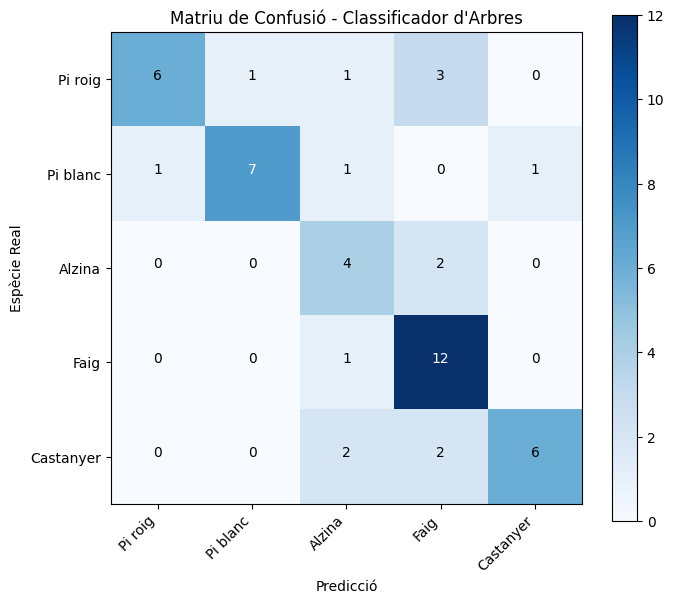

              precision    recall  f1-score   support

     Pi roig       0.86      0.55      0.67        11
    Pi blanc       0.88      0.70      0.78        10
      Alzina       0.44      0.67      0.53         6
        Faig       0.63      0.92      0.75        13
   Castanyer       0.86      0.60      0.71        10

    accuracy                           0.70        50
   macro avg       0.73      0.69      0.69        50
weighted avg       0.75      0.70      0.70        50



In [10]:
# Step 9: Validation Evaluation & Confusion Matrix
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

all_preds = []
all_targets = []

head.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        feats = feature_extractor(images)
        feats = nn.functional.adaptive_avg_pool2d(feats, (1, 1)).flatten(1)
        outputs = head(feats)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

cm = confusion_matrix(all_targets, all_preds)
class_names = [t[2] for t in TREE_CATALOG]  # Catalan display names

plt.figure(figsize=(7, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Matriu de Confusió - Classificador d\'Arbres')
plt.colorbar()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names, rotation=45, ha='right')
plt.yticks(tick_marks, class_names)

thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 horizontalalignment='center',
                 color='white' if cm[i, j] > thresh else 'black')

plt.tight_layout()
plt.ylabel('Espècie Real')
plt.xlabel('Predicció')
plt.show()

print(classification_report(all_targets, all_preds, target_names=class_names))


In [11]:
# Step 10: Binary Serialization & Model Export
import struct

# 1. Save tree_labels.txt
labels_file = EXPORT_DIR / "tree_labels.txt"
with open(labels_file, "w", encoding="utf-8") as f:
    for t in TREE_CATALOG:
        f.write(f"{t[0]}\n")
print(f"✓ Exported {len(TREE_CATALOG)} labels to {labels_file}")

# 2. Save tree_classifier_head.bin (Float32 biases followed by weights)
head_file = EXPORT_DIR / "tree_classifier_head.bin"
num_classes = len(TREE_CATALOG)
feature_dim = 1280

with open(head_file, "wb") as f:
    # Write biases (5 Float32)
    for b in best_biases:
        f.write(struct.pack("<f", float(b)))
    # Write weights (5 x 1280 Float32 row-major)
    for row in best_weights:
        for w in row:
            f.write(struct.pack("<f", float(w)))

head_bytes = head_file.stat().st_size
expected_bytes = (num_classes * 4) + (num_classes * feature_dim * 4)
print(f"✓ Exported {head_bytes} bytes to {head_file} (expected: {expected_bytes} bytes)")
assert head_bytes == expected_bytes, f"Size mismatch: {head_bytes} vs {expected_bytes}"

# 3. Export quantized MobileNetV2 backbone (tree_classifier.tflite)
import tensorflow as tf
mobilenet = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    pooling='avg',
    weights='imagenet'
)

converter = tf.lite.TFLiteConverter.from_keras_model(mobilenet)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

tflite_file = EXPORT_DIR / "tree_classifier.tflite"
with open(tflite_file, "wb") as f:
    f.write(tflite_model)
print(f"✓ Exported MobileNetV2 backbone ({len(tflite_model) / (1024*1024):.2f} MB) to {tflite_file}")


✓ Exported 5 labels to export/tree_labels.txt
✓ Exported 25620 bytes to export/tree_classifier_head.bin (expected: 25620 bytes)
Saved artifact at '/tmp/tmpqti_f8j8'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1280), dtype=tf.float32, name=None)
Captures:
  134890304175568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304173072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304175184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304174800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304175952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304172880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304175376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304171920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134890304174992: Tensor

In [12]:
# Step 11: Export & Download Model Files
import shutil

tflite_path = EXPORT_DIR / "tree_classifier.tflite"
head_bin_path = EXPORT_DIR / "tree_classifier_head.bin"
labels_path = EXPORT_DIR / "tree_labels.txt"

# 1. If running locally or in VS Code with workspace root accessible, auto-copy to assets/models/
local_assets_targets = [Path("assets/models"), Path("../assets/models")]
copied_locally = False
for target in local_assets_targets:
    if target.exists() and target.is_dir():
        for f in [tflite_path, head_bin_path, labels_path]:
            shutil.copy2(f, target / f.name)
        print(f"✅ Automatically copied trained models to local workspace: {target.resolve()}/")
        copied_locally = True
        break

# 2. If Google Drive is mounted, also back up to Google Drive
drive_models_dir = Path("/content/drive/MyDrive/boscdex_tree_models")
if Path("/content/drive/MyDrive").exists():
    drive_models_dir.mkdir(parents=True, exist_ok=True)
    for f in [tflite_path, head_bin_path, labels_path]:
        shutil.copy2(f, drive_models_dir / f.name)
    print(f"💾 Saved a permanent copy to Google Drive: {drive_models_dir}/")

# 3. Attempt direct browser download (works in web Colab)
try:
    from google.colab import files
    print("Triggering browser download of tree model assets...")
    files.download(str(tflite_path))
    files.download(str(head_bin_path))
    files.download(str(labels_path))
except Exception as e:
    print(f"Browser download skipped/not supported: {e}")

print()
print("🎉 Done! Copy these 3 files into your local project:")
print("   1. assets/models/tree_classifier.tflite")
print("   2. assets/models/tree_classifier_head.bin")
print("   3. assets/models/tree_labels.txt")
print()
print("Then verify with:")
print("   flutter test test/unit_tests/domain/tree_model_real_images_test.dart")

💾 Saved a permanent copy to Google Drive: /content/drive/MyDrive/boscdex_tree_models/
Triggering browser download of tree model assets...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 Done! Copy these 3 files into your local project:
   1. assets/models/tree_classifier.tflite
   2. assets/models/tree_classifier_head.bin
   3. assets/models/tree_labels.txt

Then verify with:
   flutter test test/unit_tests/domain/tree_model_real_images_test.dart
